# Paper results — one notebook, end to end

Regenerates **every figure and table** in *"From Articles to Publishers"* from the
model outputs in `Classification/`, plus the GPT-5-mini zero-shot baseline.

Run it top to bottom. There is no hidden state: every cell depends only on cells
above it, and nothing is written outside `Results/figures`, `Results/tables` and
`Results/derived`.

**What this replaces.** Notebooks `4 - Plotter`, `5 - Political Error Analysis`,
`6 - Domain inpact analisys` and the enrichment half of `7 - Get prediction scores`.
Those are kept for provenance but are no longer the source of any paper artefact.

**Three defects in the old pipeline that this one fixes** (details in
`2-analysis/FINDINGS.md`):

1. `4 - Plotter.ipynb` read `llama.csv` into `robertaDf` and `roberta.csv` into
   `llamaDf`, so the published **article-level F1 and tolerant accuracy have
   RoBERTa and Llama swapped**. The swap was also baked into
   `confusion_matrices_all_models.csv`, which notebook 5 then read.
2. "Mean error direction" was computed two different ways under one name —
   divided by the number of errors in one place, by the number of articles in
   another. The paper states the first formula but reports the second.
3. Publisher aggregation breaks ties toward the **lowest** reliability class,
   silently deciding 2.5–4.6% of publishers. Never documented.

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)

# Make the `irgood` package importable no matter where Jupyter was started.
HERE = Path.cwd()
if not (HERE / "irgood").exists() and (HERE / "2-analysis" / "irgood").exists():
    HERE = HERE / "2-analysis"
sys.path.insert(0, str(HERE))

import pandas as pd

from irgood import config as C
from irgood import data, metrics, aggregate, bias, plots

# use_latex=True reproduces the paper's PGF/serif rendering but needs a working
# TeX installation. Off by default so this notebook runs anywhere.
plots.set_style(use_latex=False)
C.ensure_output_dirs()

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

print("repo root :", C.REPO_ROOT)
print("figures   ->", C.FIGURES_DIR)
print("tables    ->", C.TABLES_DIR)
print("derived   ->", C.DERIVED_DIR)

repo root : /home/john/Repos/IrForGood
figures   -> /home/john/Repos/IrForGood/Results/figures
tables    -> /home/john/Repos/IrForGood/Results/tables
derived   -> /home/john/Repos/IrForGood/Results/derived


## 2. Load and validate

One tidy table for everything: `model | article_id | url | domain | fold | y_true | y_pred`,
plus the publisher's political leaning.

The validation step is not decoration. It asserts that every model saw the same
ground truth for the same article — the check that would have caught the
RoBERTa/Llama swap immediately.

In [2]:
preds = data.load_all_predictions(include_gpt=True, with_leaning=True)

report = data.validate(preds)
display(report.round(4))
print("Same ground truth across all models:", report.attrs["ground_truth_consistent"])

# Fine-tuned models only: used wherever the paper compares the four architectures.
ft = preds[preds["model"].isin(C.MODEL_ORDER)].copy()

preds.to_csv(C.DERIVED_DIR / "predictions_long.csv", index=False)
print("\nSaved:", C.DERIVED_DIR / "predictions_long.csv", preds.shape)

,model,n_articles,n_publishers,duplicate_article_ids,labels_out_of_range,preds_out_of_range,accuracy
0,BERT,19476,439,0,0,0,0.5827
1,RoBERTa,19476,439,0,0,0,0.6034
2,Llama,19476,439,0,0,0,0.5997
3,Mistral,19476,439,0,0,0,0.6116
4,GPT-5-mini (zero-shot),19469,439,0,0,0,0.2452


Same ground truth across all models: True



Saved: /home/john/Repos/IrForGood/Results/derived/predictions_long.csv (97373, 10)


## 3. Stage 1 — article-level reliability estimation

Two views of the same thing: metrics pooled over all five test folds (quoted in
the text) and the per-fold spread (the box plot).

,model,n_articles,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Tolerant_0.5,Tolerant_1.0
0,BERT,19476,0.5827,0.5293,0.5193,0.5227,0.7017,0.8207
1,RoBERTa,19476,0.6034,0.5466,0.5440,0.5444,0.7169,0.8303
2,Llama,19476,0.5997,0.5604,0.5521,0.5547,0.7187,0.8377
3,Mistral,19476,0.6116,0.5548,0.5530,0.5531,0.7231,0.8346
4,GPT-5-mini (zero-shot),19469,0.2452,0.2272,0.2211,0.2003,0.4288,0.6123


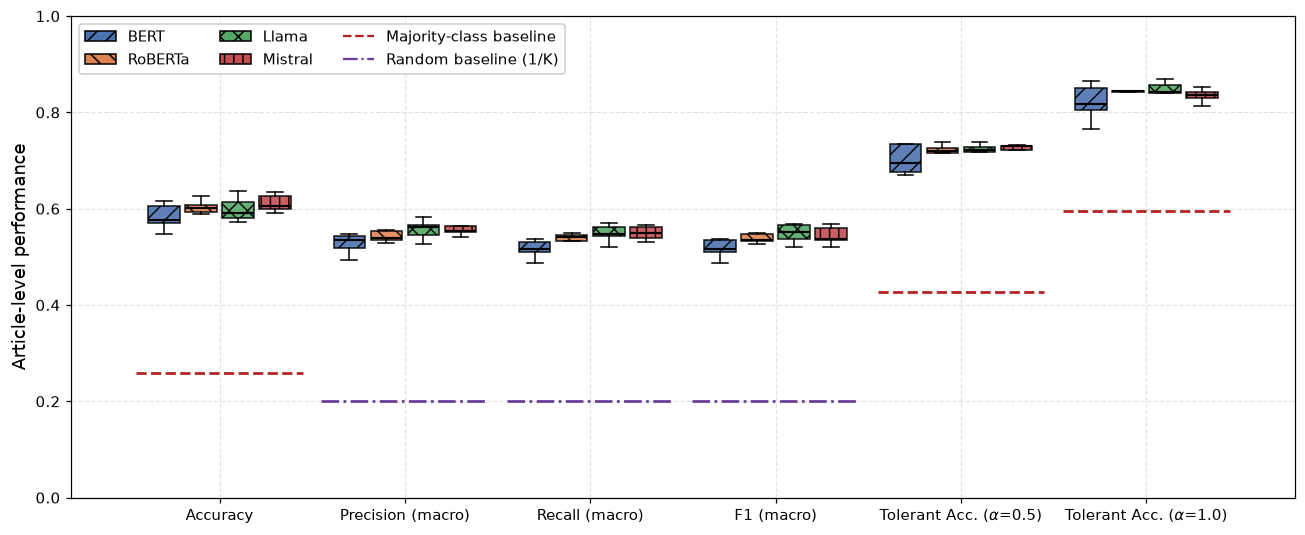

In [3]:
article_tbl = aggregate.article_metrics(preds)
display(article_tbl.round(4))

per_fold = data.load_per_fold_metrics()
y_true_articles = ft[ft["model"] == C.MODEL_ORDER[0]]["y_true"]

plots.fig_article_metrics_boxplot(per_fold, y_true_articles)
article_tbl.to_csv(C.TABLES_DIR / "article_level_metrics.csv", index=False)

### The same figure with the zero-shot baseline in it

Two versions are produced: `article_metrics_boxplot.pdf` with the four
fine-tuned models, and `article_metrics_boxplot_with_gpt.pdf` with GPT-5-mini
added as a fifth series.

GPT can be boxed like the others because all four fine-tuned models share one
`article -> fold` map, so its predictions can be scored on the same five
publisher-disjoint partitions. The recomputed per-fold metrics agree with the
ones the training runs wrote out to floating-point precision, so the two
versions of the figure are built from the same numbers.

Read the boxes with one caveat in mind: for the fine-tuned models the spread
reflects a different training set *and* a different test set, whereas GPT is
never trained, so its spread is test-partition variability alone. Note that it
is nonetheless the **widest** of the five (accuracy range 0.082 across folds
against 0.038-0.069), i.e. the zero-shot scorer is the least stable across
publisher subsets, not the most.

max |stored - recomputed| across fine-tuned folds: 5.55e-17



Accuracy spread across the five folds:


,fold_min,fold_max,range
model,,,
BERT,0.5473,0.6166,0.0693
RoBERTa,0.5883,0.6261,0.0378
Llama,0.5733,0.6371,0.0638
Mistral,0.5918,0.6341,0.0423
GPT-5-mini (zero-shot),0.2129,0.2949,0.0820


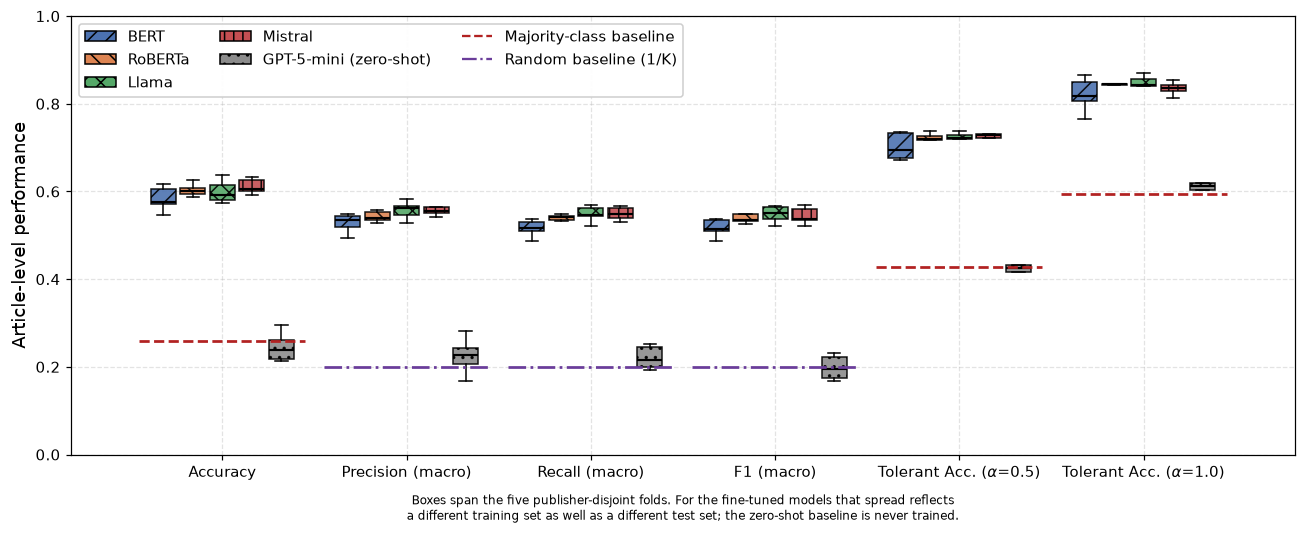

In [4]:
# Recomputed per fold from the predictions, so the zero-shot baseline -- which
# has no training run and therefore no stored per-fold CSV -- can be included.
per_fold_all = data.per_fold_metrics(preds)

# Consistency check: recomputation must agree with what the training runs saved.
check = per_fold.merge(per_fold_all, on=["model", "fold"], suffixes=("_stored", "_recomputed"))
max_drift = max(
    (check[f"{m}_stored"] - check[f"{m}_recomputed"]).abs().max()
    for m in ["Accuracy", "F1_Macro", "Tolerant_1.0"]
)
print(f"max |stored - recomputed| across fine-tuned folds: {max_drift:.2e}")

plots.fig_article_metrics_boxplot(
    per_fold_all, y_true_articles,
    name="article_metrics_boxplot_with_gpt", include_gpt=True,
)

spread = (
    per_fold_all.groupby("model", observed=True)["Accuracy"]
    .agg(fold_min="min", fold_max="max")
    .assign(range=lambda d: d["fold_max"] - d["fold_min"])
)
print("\nAccuracy spread across the five folds:")
display(spread.round(4))

per_fold_all.to_csv(C.TABLES_DIR / "per_fold_metrics.csv", index=False)

### Uncertainty

Bootstrap confidence intervals that resample **publishers**, not articles.
Articles from one outlet share a label and are not independent observations, so
an article-level bootstrap would understate the interval.

In [5]:
rows = []
for model, g in ft.groupby("model", observed=True):
    point, lo, hi = metrics.bootstrap_ci(
        g["y_true"].to_numpy(), g["y_pred"].to_numpy(),
        metric="Accuracy", n_boot=2000, cluster=g["domain"].to_numpy(),
    )
    rows.append({"model": model, "accuracy": point, "ci_low": lo, "ci_high": hi})

ci_tbl = pd.DataFrame(rows)
display(ci_tbl.round(4))
print("Note how wide these are, and how much they overlap: once publishers are")
print("the resampling unit, the four models are not cleanly separable.")
ci_tbl.to_csv(C.TABLES_DIR / "article_accuracy_bootstrap_ci.csv", index=False)

,model,accuracy,ci_low,ci_high
0,BERT,0.5827,0.5326,0.6311
1,RoBERTa,0.6034,0.5512,0.6550
2,Llama,0.5997,0.5452,0.6520
3,Mistral,0.6116,0.5581,0.6631


Note how wide these are, and how much they overlap: once publishers are
the resampling unit, the four models are not cleanly separable.


## 4. Stage 2 — publisher-level inference

Majority vote over each publisher's articles. The tie-break is reported rather
than assumed: it decides a small but non-trivial share of publishers, always in
the same direction (toward lower reliability), and by a different amount per
model.

,model,n_publishers,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Tolerant_0.5,Tolerant_1.0
0,BERT,439,0.6651,0.5605,0.5560,0.5513,0.7677,0.8702
1,RoBERTa,439,0.6902,0.6175,0.6025,0.6048,0.7825,0.8747
2,Llama,439,0.6651,0.5847,0.5826,0.5777,0.7722,0.8793
3,Mistral,439,0.6834,0.5901,0.5900,0.5888,0.7699,0.8565
4,GPT-5-mini (zero-shot),439,0.2392,0.2070,0.2269,0.1792,0.3929,0.5467



Publishers decided by the tie-break rule:


,model,n_publishers,n_tied,pct_tied
0,BERT,439,13,2.96
1,RoBERTa,439,20,4.56
2,Llama,439,15,3.42
3,Mistral,439,11,2.51


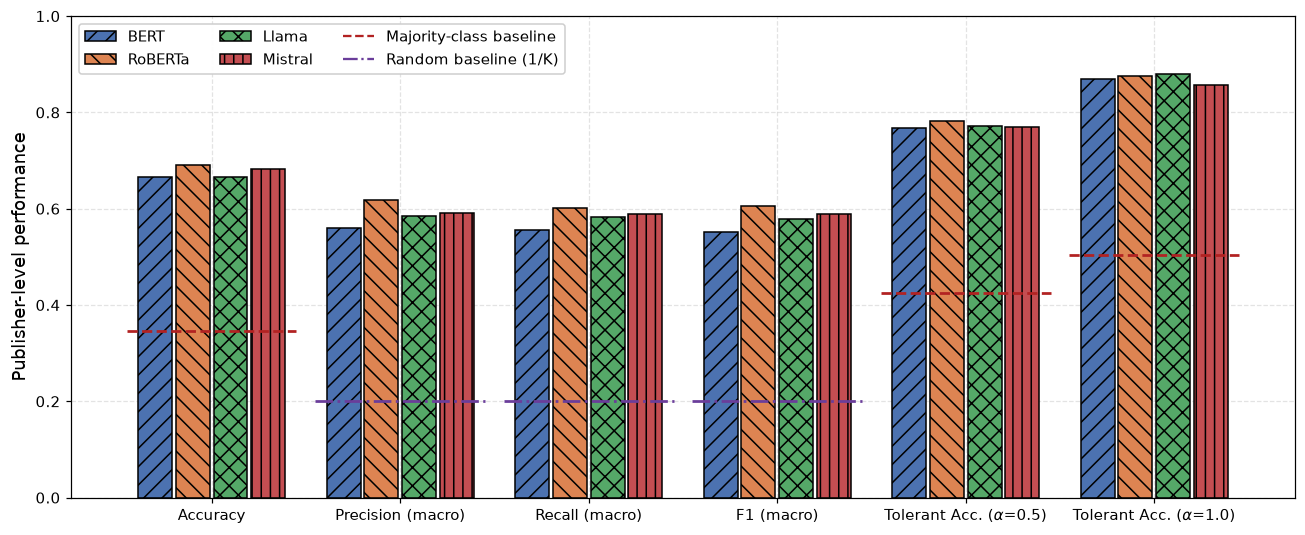

In [6]:
pub_ft  = aggregate.aggregate_to_publisher(ft)
pub_all = aggregate.aggregate_to_publisher(preds)

publisher_tbl = aggregate.publisher_metrics(pub_all)
display(publisher_tbl.round(4))

print("\nPublishers decided by the tie-break rule:")
display(aggregate.tie_report(ft).round(2))

y_true_publishers = pub_ft[pub_ft["model"] == C.MODEL_ORDER[0]]["y_true"]
plots.fig_publisher_metrics(aggregate.publisher_metrics(pub_ft), y_true_publishers)

publisher_tbl.to_csv(C.TABLES_DIR / "publisher_level_metrics.csv", index=False)
pub_all.to_csv(C.DERIVED_DIR / "publisher_predictions.csv", index=False)

### How much does aggregation actually buy?

The paper compares 0.60 at article level with 0.69 at publisher level, but those
two numbers differ in **two** ways at once: the unit of evaluation *and* the
weighting, since article-level accuracy is dominated by prolific publishers.

This curve separates them. Every point uses the same unit — the publisher — and
the same fixed set of publishers; only `k`, the number of articles voted,
changes. `k=1` is therefore the honest baseline, and the rise above it is what
aggregation contributes and nothing else.

,model,k,accuracy_mean,accuracy_std,tolerant_1.0_mean,n_publishers,fixed_population
0,BERT,1,0.6698,0.0155,0.8552,270,True
1,BERT,3,0.6765,0.0138,0.8530,270,True
2,BERT,5,0.6854,0.0126,0.8680,270,True
3,BERT,10,0.6998,0.0131,0.8865,270,True
4,BERT,20,0.6985,0.0088,0.8941,270,True
5,BERT,30,0.7011,0.0118,0.8993,270,True
6,RoBERTa,1,0.6931,0.0133,0.8661,270,True
7,RoBERTa,3,0.6965,0.0162,0.8576,270,True
8,RoBERTa,5,0.7044,0.0170,0.8746,270,True
9,RoBERTa,10,0.7119,0.0130,0.8800,270,True



Accuracy gained by going from 1 to 30 articles per publisher:


k,gain_1_to_30
model,
BERT,0.0313
RoBERTa,0.0237
Llama,0.0326
Mistral,0.0165


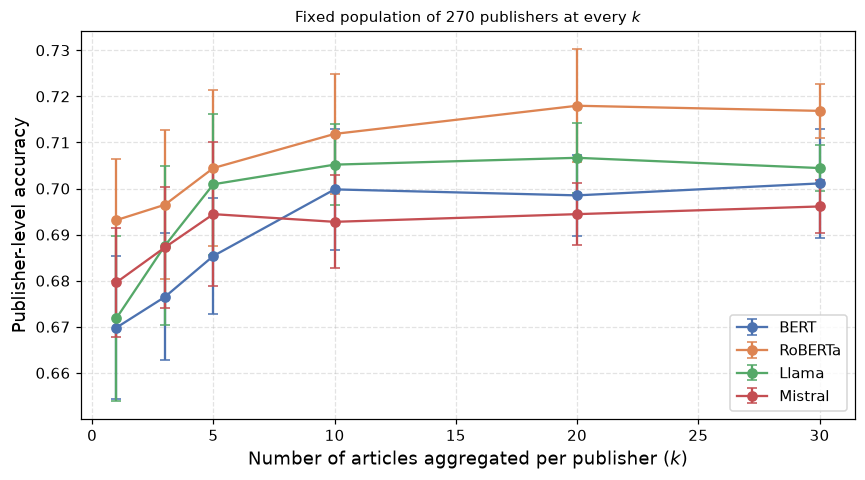

In [7]:
curve = aggregate.aggregation_curve(
    ft, k_values=(1, 3, 5, 10, 20, 30), n_repeats=20, fixed_population=True
)
display(curve.round(4))

plots.fig_aggregation_curve(curve)
curve.to_csv(C.TABLES_DIR / "aggregation_curve.csv", index=False)

gain = (
    curve.pivot_table(index="model", columns="k", values="accuracy_mean", observed=True)
    .assign(gain_1_to_30=lambda d: d[30] - d[1])
)
print("\nAccuracy gained by going from 1 to 30 articles per publisher:")
display(gain[["gain_1_to_30"]].round(4))

## 5. Error structure by reliability level

`mean_error_direction` takes an explicit `over=` argument because the two
choices give materially different numbers and the old code used both.
`over="all"` reproduces the published figures; `over="errors"` is what the
paper's equation actually defines. Pick one and say which in the text.

model,BERT,RoBERTa,Llama,Mistral
class_label,,,,
l1,0.171,0.140,0.162,0.132
l2,0.640,0.562,0.533,0.546
l3,0.354,0.321,0.370,0.324
l4,0.430,0.463,0.459,0.450
l5,0.808,0.794,0.717,0.783


Denominator = all articles (reproduces the published figure):


model,BERT,RoBERTa,Llama,Mistral
y_true,,,,
0,0.39,0.31,0.33,0.27
1,0.98,0.80,0.88,0.78
2,0.12,0.03,0.05,0.10
3,-0.36,-0.40,-0.27,-0.41
4,-1.29,-1.37,-1.20,-1.36


Denominator = misclassified only (the paper's stated formula):


model,BERT,RoBERTa,Llama,Mistral
y_true,,,,
0,2.30,2.23,2.04,2.02
1,1.53,1.42,1.65,1.42
2,0.35,0.10,0.13,0.30
3,-0.83,-0.86,-0.59,-0.90
4,-1.60,-1.72,-1.67,-1.74


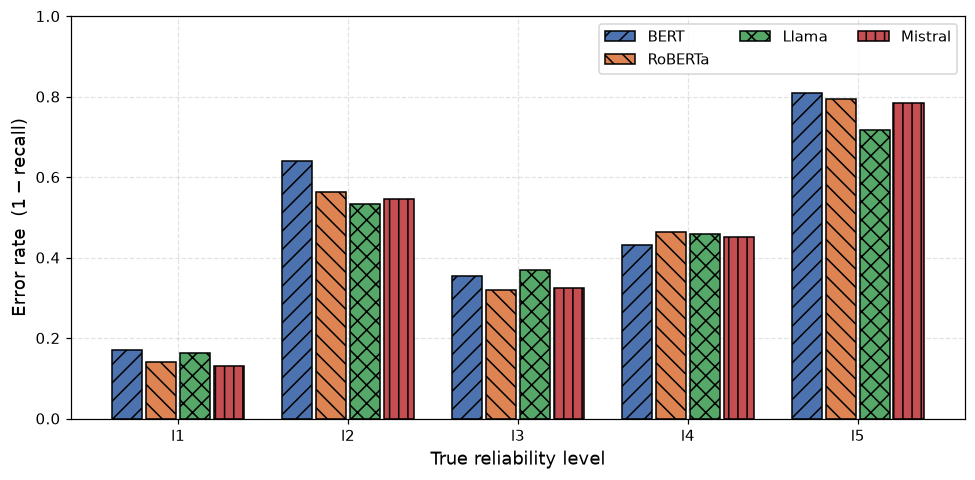

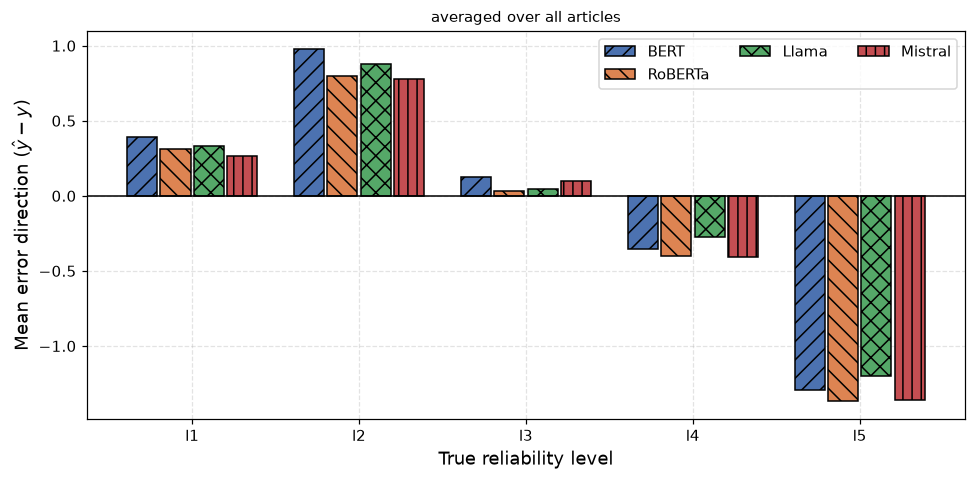

In [8]:
err_by_class = metrics.error_rate_by_class(ft)
display(err_by_class.pivot_table(index="class_label", columns="model",
                                 values="error_rate", observed=True).round(3))
plots.fig_error_rate_by_class(err_by_class)

med_all    = metrics.mean_error_direction(ft, ["model", "y_true"], over="all")
med_errors = metrics.mean_error_direction(ft, ["model", "y_true"], over="errors")

print("Denominator = all articles (reproduces the published figure):")
display(med_all.pivot_table(index="y_true", columns="model", values="med", observed=True).round(2))
print("Denominator = misclassified only (the paper's stated formula):")
display(med_errors.pivot_table(index="y_true", columns="model", values="med", observed=True).round(2))

plots.fig_med_by_class(med_all)
err_by_class.to_csv(C.TABLES_DIR / "error_rate_by_class.csv", index=False)
pd.concat([med_all, med_errors]).to_csv(C.TABLES_DIR / "med_by_class.csv", index=False)

## 6. Political leaning

### 6.1 Look at the corpus first

Reliability and leaning are strongly associated in the media ecosystem itself.
That association is the confound: an apparent political bias in the errors may
be a reliability effect in disguise. Read this table before the tests.

,l1,l2,l3,l4,l5
leaning,,,,,
Far Left,86,355,6,408,160
Slightly Left,0,245,174,1325,663
Non labelled,71,635,3189,1964,563
Slightly Right,4245,782,960,961,542
Far Right,469,999,291,383,0


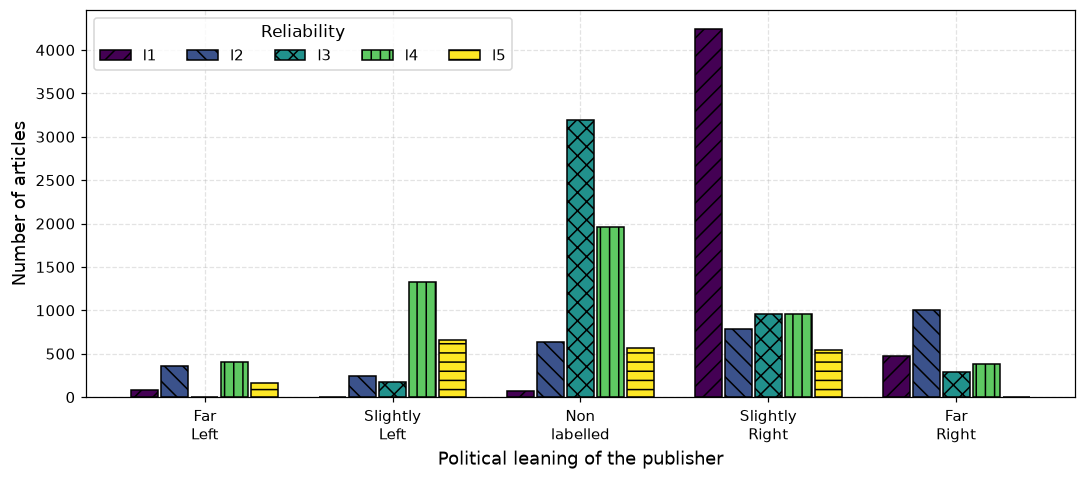

In [9]:
crosstab = bias.leaning_by_reliability_crosstab(ft)
display(crosstab)
plots.fig_leaning_distribution(crosstab)
crosstab.to_csv(C.TABLES_DIR / "leaning_by_reliability.csv")

### 6.2 Error rates and error direction by leaning

model,BERT,RoBERTa,Llama,Mistral
leaning,,,,
Far Left,0.705,0.716,0.719,0.635
Slightly Left,0.577,0.515,0.473,0.566
Non labelled,0.332,0.319,0.324,0.305
Slightly Right,0.324,0.316,0.336,0.310
Far Right,0.683,0.627,0.622,0.594


model,BERT,RoBERTa,Llama,Mistral
leaning,,,,
Far Left,0.464,0.538,0.629,0.771
Slightly Left,-0.819,-0.731,-0.599,-0.537
Non labelled,0.097,-0.026,0.264,0.069
Slightly Right,0.116,-0.308,-0.081,-0.392
Far Right,1.001,0.528,0.517,0.332


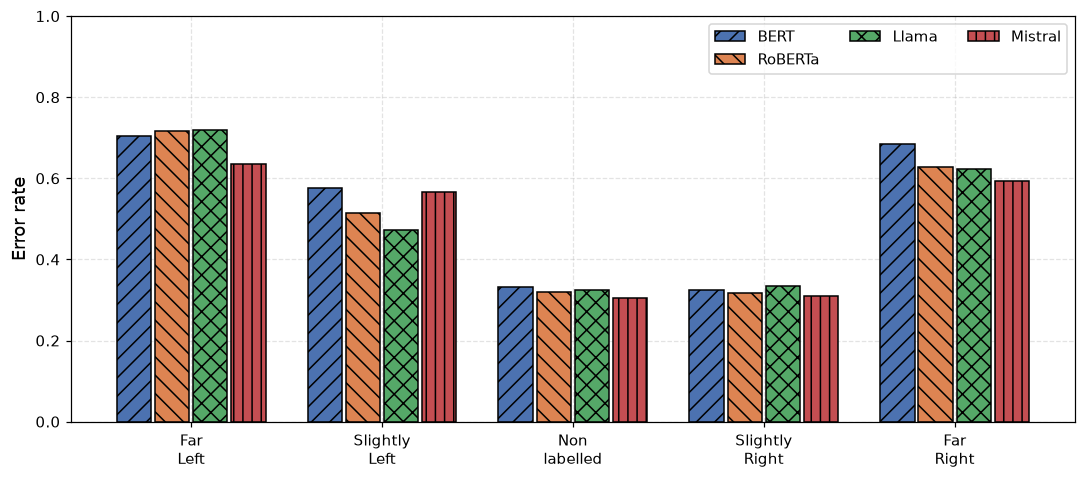

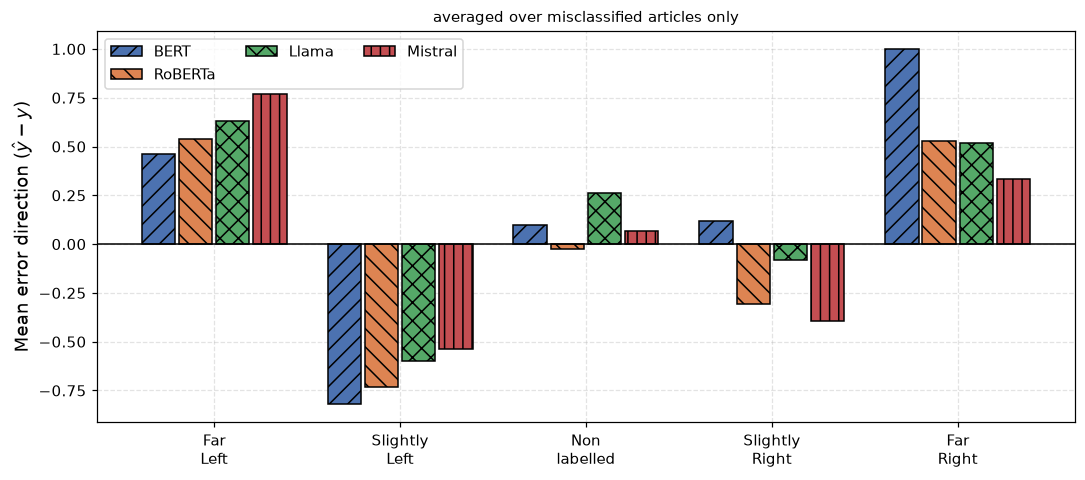

In [10]:
er_leaning = bias.error_rate_by_leaning(ft)
display(er_leaning.pivot_table(index="leaning", columns="model",
                               values="error_rate", observed=True).round(3))
plots.fig_error_rate_by_leaning(er_leaning)

med_leaning = bias.med_by_leaning(ft, over="errors")
display(med_leaning.pivot_table(index="leaning", columns="model",
                                values="med", observed=True).round(3))
plots.fig_med_by_leaning(med_leaning)

er_leaning.to_csv(C.TABLES_DIR / "error_rate_by_leaning.csv", index=False)
med_leaning.to_csv(C.TABLES_DIR / "med_by_leaning.csv", index=False)

### 6.3 Is the association real? Three tests, increasing in rigour

The published chi-square treated 19,476 articles as independent observations.
They are not: leaning and reliability are properties of the **publisher**, so
there are really 439 clusters. That inflates chi-square roughly by the average
cluster size, which is why the original statistic was in the thousands.

Three versions are computed so the effect of the correction is visible:

1. **article level, uncorrected** — reproduces the published table;
2. **publisher level** — one observation per publisher, so independence holds;
3. **logistic regression with publisher-clustered standard errors**, optionally
   controlling for the true reliability level, which addresses the confound and
   the clustering at the same time.

In [11]:
chi_article   = bias.chi_square_article_level(ft)
chi_publisher = bias.chi_square_publisher_level(pub_ft)

comparison = pd.concat([chi_article, chi_publisher], ignore_index=True)
display(comparison.round(4))
comparison.to_csv(C.TABLES_DIR / "chi_square_comparison.csv", index=False)

,model,unit,n,chi2,p_value,dof,cramers_v,min_expected,pct_expected_lt5
0,BERT,article (uncorrected),19476,1684.1301,0.0000,4,0.2941,NaN,NaN
1,RoBERTa,article (uncorrected),19476,1418.3147,0.0000,4,0.2699,NaN,NaN
2,Llama,article (uncorrected),19476,1207.8251,0.0000,4,0.2490,NaN,NaN
3,Mistral,article (uncorrected),19476,1343.9796,0.0000,4,0.2627,NaN,NaN
4,BERT,publisher (clustered),439,44.8447,0.0000,4,0.3196,6.6970,0.0
5,RoBERTa,publisher (clustered),439,18.8263,0.0009,4,0.2071,6.1959,0.0
6,Llama,publisher (clustered),439,23.8782,0.0001,4,0.2332,6.6970,0.0
7,Mistral,publisher (clustered),439,24.0649,0.0001,4,0.2341,6.3326,0.0


In [12]:
# Leaning effects with clustered SEs, with and without controlling for reliability.
mixed_raw        = bias.mixed_effects_by_leaning(ft, control_for_reliability=False)
mixed_controlled = bias.mixed_effects_by_leaning(ft, control_for_reliability=True)

leaning_terms = mixed_controlled[mixed_controlled["term"].str.contains("leaning", na=False)]
print("Odds of an error vs the 'Non labelled' reference, controlling for reliability:")
display(leaning_terms[["model", "term", "odds_ratio", "p_value", "ci_low", "ci_high"]].round(4))

pd.concat([mixed_raw, mixed_controlled]).to_csv(
    C.TABLES_DIR / "leaning_logit_clustered.csv", index=False
)

Odds of an error vs the 'Non labelled' reference, controlling for reliability:


,model,term,odds_ratio,p_value,ci_low,ci_high
1,BERT,leaning[T.Far Left],4.8124,0.0025,0.5518,2.5906
2,BERT,leaning[T.Slightly Left],2.1101,0.0246,0.0955,1.3980
3,BERT,leaning[T.Slightly Right],2.1121,0.0349,0.0531,1.4423
4,BERT,leaning[T.Far Right],6.5223,0.0008,0.7813,2.9691
10,RoBERTa,leaning[T.Far Left],5.5490,0.0048,0.5226,2.9047
11,RoBERTa,leaning[T.Slightly Left],1.4913,0.3600,-0.4560,1.2554
12,RoBERTa,leaning[T.Slightly Right],2.4569,0.0162,0.1663,1.6315
13,RoBERTa,leaning[T.Far Right],6.1815,0.0018,0.6792,2.9639
19,Llama,leaning[T.Far Left],6.2893,0.0031,0.6197,3.0580
20,Llama,leaning[T.Slightly Left],1.4077,0.4357,-0.5178,1.2018


## 7. Zero-shot GPT-5-mini baseline

The comparison the second TCSS reviewer asked for. Same articles, same
aggregation, same metrics — the only difference is that GPT was never trained on
NewsGuard labels.

The prediction-distribution figure carries the interpretation: GPT collapses
onto the middle of the scale, which is what a model that was given the rubric
but no calibration data does.

,model,n_articles,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Tolerant_0.5,Tolerant_1.0,level,n_publishers
0,BERT,19476.0,0.5827,0.5293,0.5193,0.5227,0.7017,0.8207,article,NaN
1,RoBERTa,19476.0,0.6034,0.5466,0.5440,0.5444,0.7169,0.8303,article,NaN
2,Llama,19476.0,0.5997,0.5604,0.5521,0.5547,0.7187,0.8377,article,NaN
3,Mistral,19476.0,0.6116,0.5548,0.5530,0.5531,0.7231,0.8346,article,NaN
4,GPT-5-mini (zero-shot),19469.0,0.2452,0.2272,0.2211,0.2003,0.4288,0.6123,article,NaN
0,BERT,NaN,0.6651,0.5605,0.5560,0.5513,0.7677,0.8702,publisher,439.0
1,RoBERTa,NaN,0.6902,0.6175,0.6025,0.6048,0.7825,0.8747,publisher,439.0
2,Llama,NaN,0.6651,0.5847,0.5826,0.5777,0.7722,0.8793,publisher,439.0
3,Mistral,NaN,0.6834,0.5901,0.5900,0.5888,0.7699,0.8565,publisher,439.0
4,GPT-5-mini (zero-shot),NaN,0.2392,0.2070,0.2269,0.1792,0.3929,0.5467,publisher,439.0



Share of GPT predictions per class (%):


y_pred
0    10.3
1    19.2
2    46.6
3    22.4
4     1.5
Name: proportion, dtype: float64

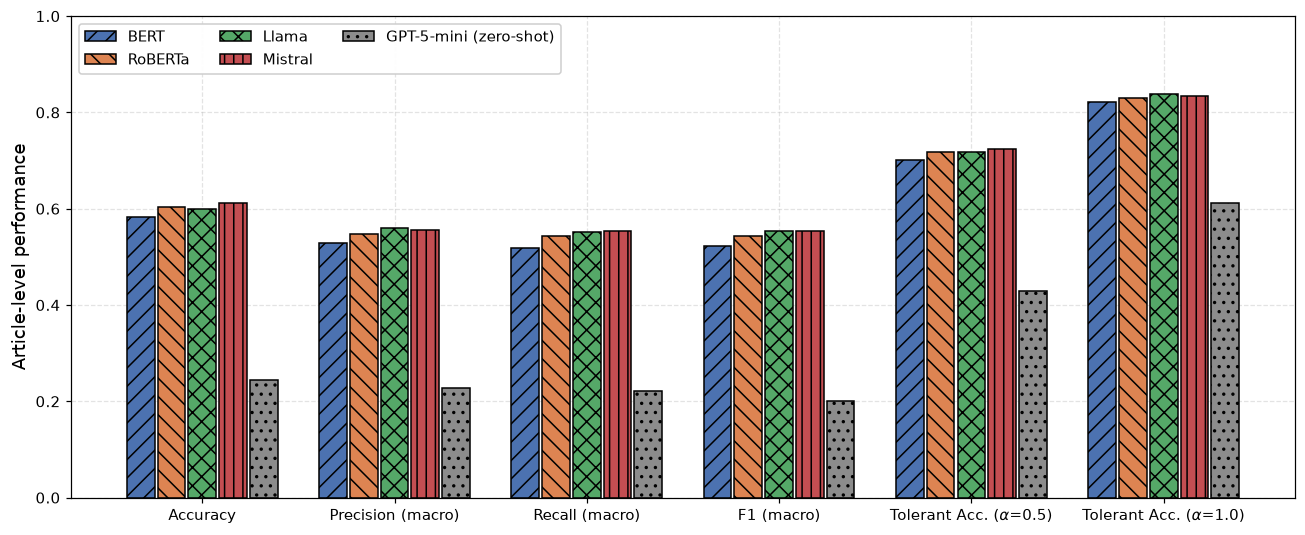

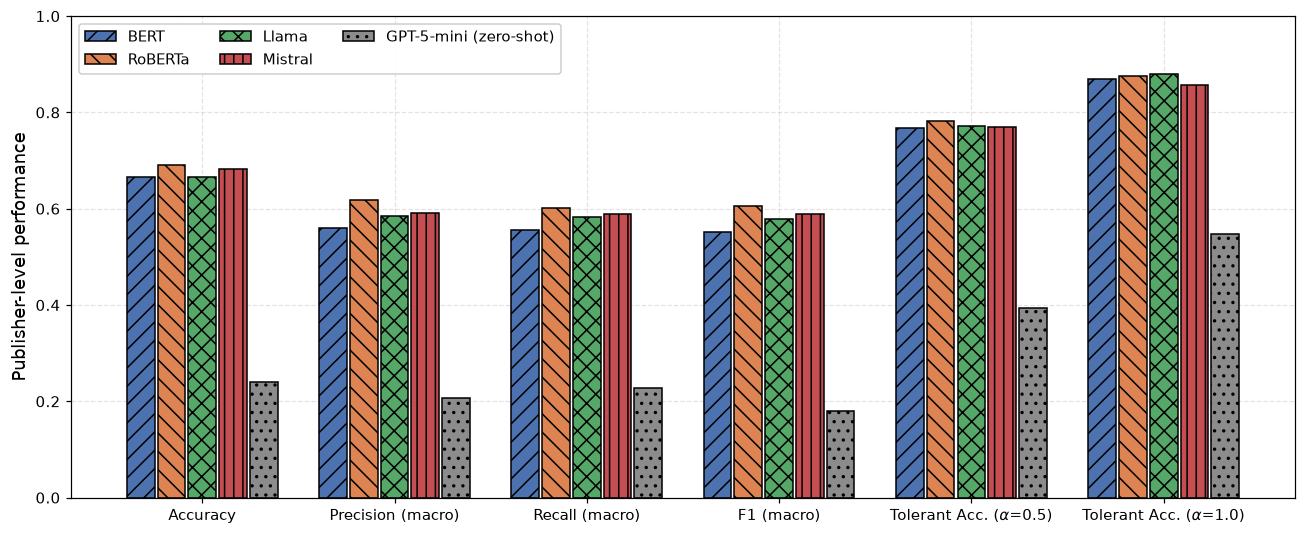

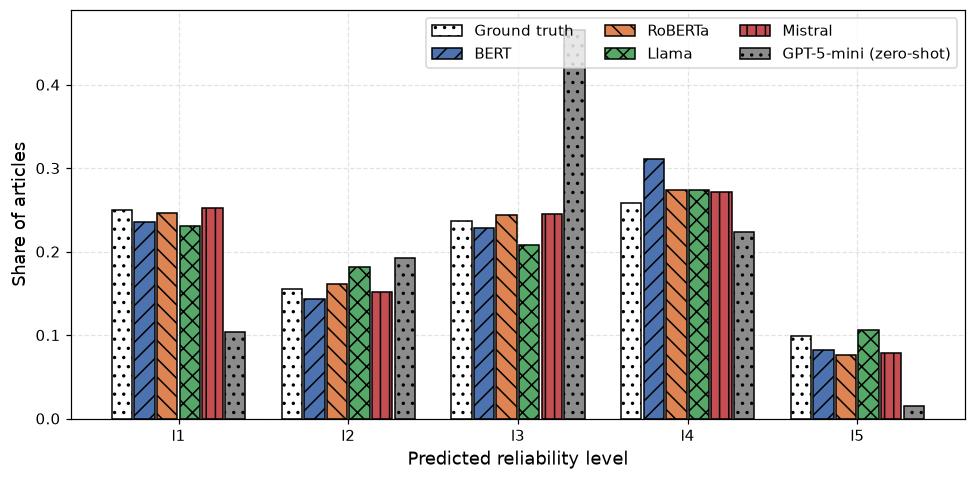

In [13]:
comparison_article   = aggregate.article_metrics(preds)
comparison_publisher = aggregate.publisher_metrics(pub_all)

plots.fig_metrics_with_gpt(comparison_article, "article")
plots.fig_metrics_with_gpt(comparison_publisher, "publisher")
plots.fig_prediction_distribution(preds)

combined = pd.concat([
    comparison_article.assign(level="article"),
    comparison_publisher.assign(level="publisher"),
])
display(combined.round(4))
combined.to_csv(C.TABLES_DIR / "finetuned_vs_zeroshot.csv", index=False)

gpt = preds[preds["model"] == C.GPT_MODEL_NAME]
print("\nShare of GPT predictions per class (%):")
display((gpt["y_pred"].value_counts(normalize=True).sort_index() * 100).round(1))

## 8. Publish the figures to the paper

Copies `Results/figures/*.pdf` into the paper's `img/` directory, so the LaTeX
source always points at regenerated output instead of a stale file someone saved
by hand. Set `PUBLISH = True` when you want the paper to pick them up.

In [14]:
import shutil

PUBLISH = False   # flip to True to overwrite the paper's figures

if PUBLISH:
    C.PAPER_IMG_DIR.mkdir(parents=True, exist_ok=True)
    for pdf in sorted(C.FIGURES_DIR.glob("*.pdf")):
        shutil.copy2(pdf, C.PAPER_IMG_DIR / pdf.name)
        print("->", C.PAPER_IMG_DIR / pdf.name)
else:
    print("PUBLISH is False. Figures produced in this run:")
    for pdf in sorted(C.FIGURES_DIR.glob("*.pdf")):
        print("  ", pdf.name)

PUBLISH is False. Figures produced in this run:
   aggregation_curve.pdf
   article_metrics_boxplot.pdf
   article_metrics_boxplot_with_gpt.pdf
   article_metrics_with_gpt.pdf
   error_rate_by_class.pdf
   error_rate_by_leaning.pdf
   leaning_distribution.pdf
   med_by_class.pdf
   med_by_leaning.pdf
   prediction_distribution.pdf
   publisher_metrics.pdf
   publisher_metrics_with_gpt.pdf
